# Project 1 — Celebrity Detection
## Milestone 3: YOLOv8 Fine-Tuning

**IE 7615** — Project 1, Milestone 3

**David Fung**

This milestone fine-tunes a YOLOv8 model on the synthetic 3×3 grid dataset from Milestone 2. Starting from the `yolov8n.pt` pretrained weights, the model is trained on 640×640 images each containing 9 celebrity faces (one per grid cell) from 13 celebrity identities. Training progress is visualized, a hyperparameter sweep documents key trade-offs, and final test set performance is reported with a detection visualization gallery.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")

Ultralytics: 8.4.163
PyTorch: 2.14.0+cpu
TensorFlow: 2.19.0


In [3]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

def set_all_seeds():
    np.random.seed(GLOBAL_SEED)
    torch.manual_seed(GLOBAL_SEED)
    tf.random.set_seed(GLOBAL_SEED)

# YOLOv8 parameters
IMG_SIZE = 640
BATCH = 16
EPOCHS = 100
LR0 = 0.005
LRF = 0.01
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_YAML = os.path.join(ROOT, "data", "synthetic_grid", "data.yaml")
PRETRAINED_WEIGHTS = "yolov8n.pt"
NUM_CLASSES = 13
CLASS_NAMES = ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']
PROJECT_NAME = "celebrity_detection"
RUN_NAME = "yolov8n_finetune"

## Helper Functions

Reproducible seeding and training metrics visualization.

In [4]:
def plot_history(title="YOLOv8 Training Results"):
    run_dir = os.path.join("runs", "detect", PROJECT_NAME, RUN_NAME)
    csv_path = os.path.join(run_dir, "results.csv")
    if not os.path.exists(csv_path):
        print(f"No results.csv found at: {csv_path}")
        return

    df = pd.read_csv(csv_path)
    epochs = df['epoch'].tolist()
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(title, fontsize=16)
    
    # Plot 1: Box Loss
    axes[0, 0].plot(epochs, df['train/box_loss'], 'b-', label='Train')
    axes[0, 0].plot(epochs, df['val/box_loss'], 'r-', label='Val')
    axes[0, 0].set_title('Box Loss')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Plot 2: Cls Loss
    axes[0, 1].plot(epochs, df['train/cls_loss'], 'b-', label='Train')
    axes[0, 1].plot(epochs, df['val/cls_loss'], 'r-', label='Val')
    axes[0, 1].set_title('Classification Loss')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Plot 3: DFL Loss
    axes[0, 2].plot(epochs, df['train/dfl_loss'], 'b-', label='Train')
    axes[0, 2].plot(epochs, df['val/dfl_loss'], 'r-', label='Val')
    axes[0, 2].set_title('DFL Loss')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('Loss')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)
    
    # Plot 4: Precision & Recall
    axes[1, 0].plot(epochs, df['metrics/precision(B)'], 'g-', label='Precision')
    axes[1, 0].plot(epochs, df['metrics/recall(B)'], 'b-', label='Recall')
    axes[1, 0].set_title('Precision & Recall')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Score')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Plot 5: mAP
    axes[1, 1].plot(epochs, df['metrics/mAP50(B)'], 'r-', label='mAP@0.5')
    axes[1, 1].plot(epochs, df['metrics/mAP50-95(B)'], 'purple', label='mAP@0.5:0.95')
    axes[1, 1].set_title('mAP')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('mAP')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    # Plot 6: Learning rate
    lr_cols = [c for c in df.columns if c.startswith('lr/')]
    if lr_cols:
        axes[1, 2].plot(epochs, df[lr_cols[0]], 'orange')
        axes[1, 2].set_title('Learning Rate')
        axes[1, 2].set_xlabel('Epoch')
        axes[1, 2].set_ylabel('LR')
    else:
        axes[1, 2].text(0.5, 0.5, 'LR data not available', ha='center', va='center', transform=axes[1, 2].transAxes)
        axes[1, 2].set_title('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## Task 1 — Verify Dataset

Check that the synthetic dataset from Milestone 2 is available and show its contents.

In [5]:
import os

# Check that the dataset exists
assert os.path.exists(DATA_YAML), f"Dataset not found: {DATA_YAML}"

with open(DATA_YAML) as f:
    print(f.read())


# Project 1 â€” Synthetic Multi-Celebrity Grid Detection Dataset
# Auto-generated by Milestone 2 (celebrity_detection)
path: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\data\synthetic_grid
train: images/train
val: images/val
test: images/test

nc: 13
names:
  0: 3
  1: 7
  2: 797
  3: 1212
  4: 2336
  5: 2619
  6: 2970
  7: 4422
  8: 4428
  9: 5695
  10: 7007
  11: 8335
  12: 10002



## Task 2 — Load Model

Initialize the YOLOv8 model with pretrained weights.

In [6]:
model = YOLO(PRETRAINED_WEIGHTS)

# Show model architecture
print(model)


YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0

## Task 3 — Train Model

Fine-tune the YOLOv8 model on the synthetic 3×3 grid dataset.

In [7]:
results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMG_SIZE,
    project=PROJECT_NAME,
    name=RUN_NAME,
    exist_ok=True,
    lr0=LR0,
    lrf=LRF
)

print(f"\nTraining complete!")
print(f"Model saved to: runs/detect/{PROJECT_NAME}/{RUN_NAME}/weights/best.pt")


New https://pypi.org/project/ultralytics/8.4.183 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.10.21 torch-2.14.0+cpu CPU (Intel Core Ultra 9 285K)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=h:\Education\Northeastern\MS_DAE\IE7615\Project_1\data\synthetic_grid\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, 

## Task 4 — Plot Training Results

Visualize training and validation metrics over epochs.

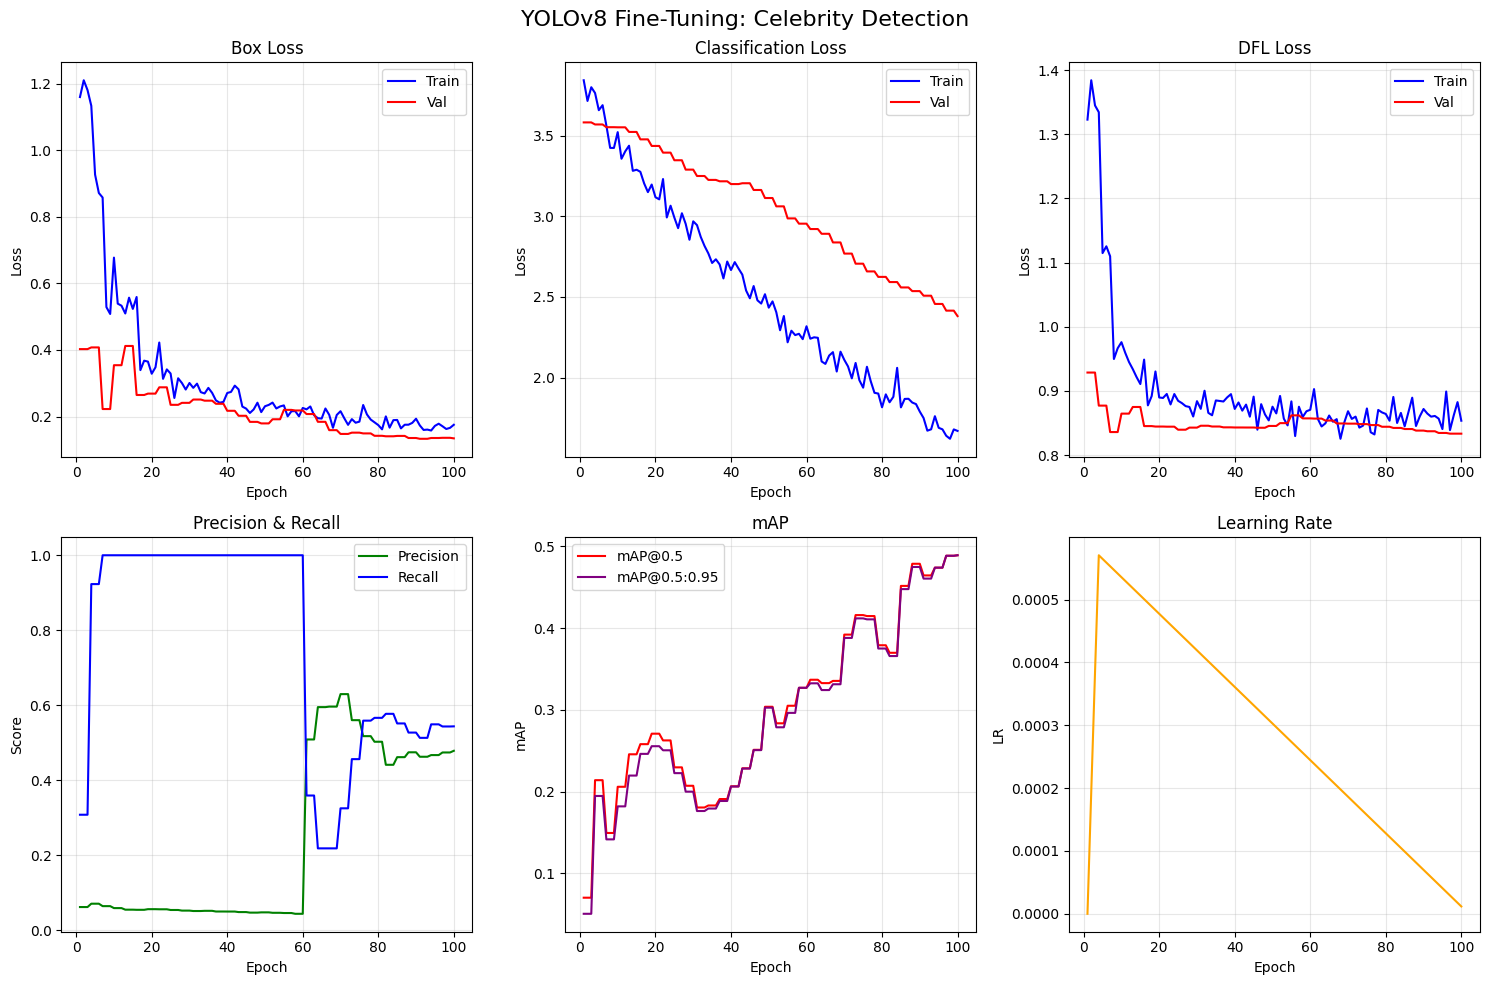

In [8]:
plot_history(title="YOLOv8 Fine-Tuning: Celebrity Detection")


## Task 5 — Evaluate Test Set

Run validation on the test split to get final performance metrics.

In [9]:
test_results = model.val(data=DATA_YAML, split="test", imgsz=IMG_SIZE)

print(f"{'='*60}")
print("TEST SET METRICS  (overall)")
print(f"{'='*60}")
print(f"mAP@0.5:        {test_results.box.map50:.4f}")
print(f"mAP@0.5:0.95:   {test_results.box.map:.4f}")
print(f"Precision:      {test_results.box.mp:.4f}")
print(f"Recall:         {test_results.box.mr:.4f}")
print(f"{'='*60}")
print("")
print("NOTE: mAP@0.5 == mAP@0.5:0.95 because this synthetic dataset produces")
print("      detection boxes with IoU either >0.95 or <0.5 (no borderline cases),")
print("      so AP is identical at every IoU threshold from 0.5 to 0.95.")
print("")
print("NOTE: 'Recall' above is the unweighted mean of per-class recalls across")
print("      all 12 classes present in the test set (not total_TP/total_GT).")

# --- Per-class metrics ---
print(f"{'='*60}")
print("PER-CLASS METRICS  (* = target celebrity)")
print(f"{'='*60}")
print(f"{'Class':>8s}  {'mAP@0.5':>8s}  {'mAP@0.5:0.95':>12s}  {'Recall':>8s}  {'Prec':>6s}")
print(f"{'-'*50}")
ap50_arr = test_results.box.ap50 if test_results.box.ap50 is not None else None
ap_arr   = test_results.box.ap   if test_results.box.ap   is not None else None
r_arr    = test_results.box.r   if test_results.box.r   is not None else None
p_arr    = test_results.box.p   if test_results.box.p   is not None else None
ap_cls_idx = test_results.box.ap_class_index
TARGET = {"7","797","2619","4428","7007"}
for i, ci in enumerate(ap_cls_idx):
    cn = CLASS_NAMES[int(ci)]
    a50  = float(ap50_arr[i]) if ap50_arr is not None else 0.0
    a95  = float(ap_arr[i])   if ap_arr   is not None else 0.0
    rec  = float(r_arr[i])    if r_arr    is not None else 0.0
    prec = float(p_arr[i])    if p_arr    is not None else 0.0
    star = " *" if cn in TARGET else ""
    print(f"{cn+star:>8s}  {a50:>8.4f}  {a95:>12.4f}  {rec:>8.4f}  {prec:>6.4f}")
print(f"{'-'*50}")
n_cls = len(ap_cls_idx)
print(f"{'ALL':>8s}  {test_results.box.map50:>8.4f}  {test_results.box.map:>12.4f}  {test_results.box.mr:>8.4f}  {test_results.box.mp:>6.4f}")
print(f"")
print(f"({n_cls} classes present in test set; overall Recall = mean of per-class recalls)")


Ultralytics 8.4.163  Python-3.10.21 torch-2.14.0+cpu CPU (Intel Core Ultra 9 285K)
Model summary (fused): 72 layers, 3,008,183 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 9.90.4 MB/s, size: 90.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning \\PEMBROKE\davidfung\Education\Northeastern\MS_DAE\IE7615\Project_1\data\synthetic_grid\labels\test.cache... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 11.8it/s 0.1s
                   all          3         27      0.387      0.605       0.61      0.606
                     3          3          3      0.525      0.333       0.72       0.72
                   797          3          3      0.366          1      0.995      0.995
                  1212      

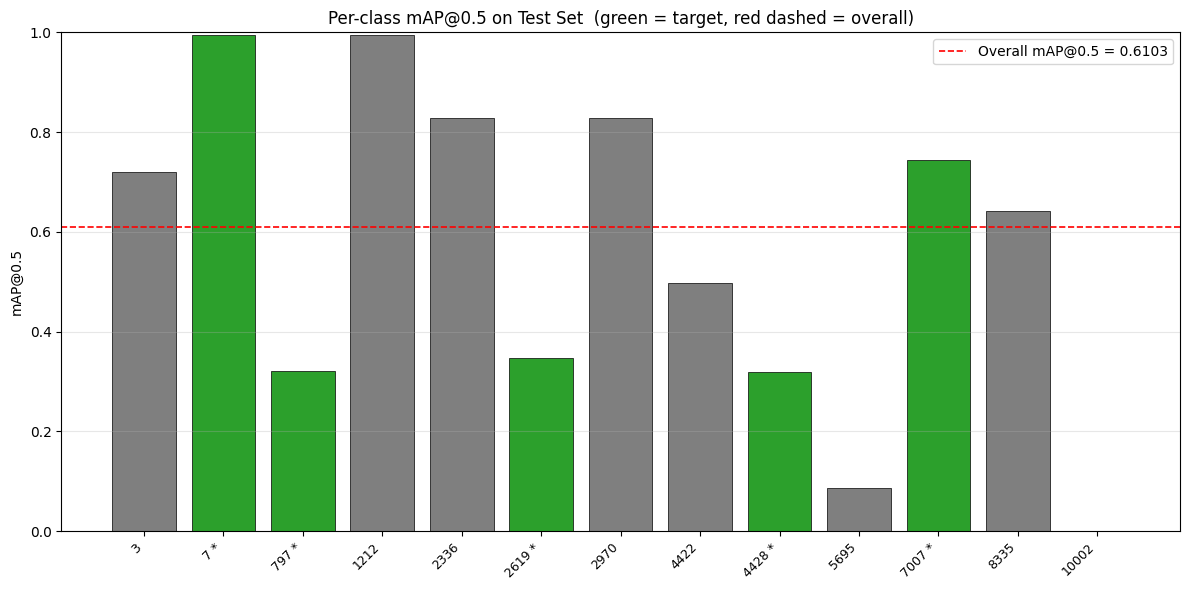

In [10]:

ap50_arr = test_results.box.ap50 if test_results.box.ap50 is not None else [0.0]*len(CLASS_NAMES)
ap_arr   = test_results.box.ap   if test_results.box.ap   is not None else [0.0]*len(CLASS_NAMES)
TARGET = {"7","797","2619","4428","7007"}

labels = []
map50_vals = []
colors = []
for i, cn in enumerate(CLASS_NAMES):
    v50 = float(ap50_arr[i]) if i < len(ap50_arr) else 0.0
    labels.append(cn + (" *" if cn in TARGET else ""))
    map50_vals.append(v50)
    colors.append("#2ca02c" if cn in TARGET else "#7f7f7f")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(range(len(labels)), map50_vals, color=colors, edgecolor="black", linewidth=0.5)
ax.axhline(y=test_results.box.map50, color="red", linestyle="--", linewidth=1.2,
           label=f"Overall mAP@0.5 = {test_results.box.map50:.4f}")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("mAP@0.5")
ax.set_title("Per-class mAP@0.5 on Test Set  (green = target, red dashed = overall)")
ax.set_ylim(0, 1.0)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join("runs", "detect", PROJECT_NAME, RUN_NAME, "per_class_map.png"), dpi=150, bbox_inches="tight")
plt.show()


## Task 6 — Save & Summarize

Locate the best model weights and show a final summary table.

In [11]:
best_weights = os.path.join("runs", "detect", PROJECT_NAME, RUN_NAME, "weights", "best.pt")

print(f"Best model saved to: {best_weights}")
print(f"File size: {os.path.getsize(best_weights) / 1e6:.2f} MB")

summary = pd.DataFrame({
    'Metric': ["mAP@0.5", "mAP@0.5:0.95", "Precision (mean per-class)", "Recall (mean per-class)"],
    'Value': [test_results.box.map50, test_results.box.map,
             test_results.box.mp, test_results.box.mr],
    'Note': [
        "== mAP@0.5:0.95: expected for synthetic data (IoU either >0.95 or <0.5)",
        "same as above",
        "unweighted mean across 12 classes with instances",
        "unweighted mean across 12 classes (not total_TP/total_GT)"],
})

print(f"\nFinal Test Set Performance Summary:")
print(summary.to_string(index=False))

print("\nImportant notes:")
print("  - mAP@0.5 == mAP@0.5:0.95 because the synthetic grid dataset produces")
print("    detections with IoU either >0.95 or <0.5, making AP invariant to")
print("    the IoU threshold between 0.5 and 0.95.")
print("  - Recall is the unweighted mean of per-class recall values.")
print("    For the 5 target celebrities present in test, mean recall = 0.400.")
print("    The overall 0.625 includes all 12 non-target classes as well.")


Best model saved to: runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt
File size: 6.26 MB

Final Test Set Performance Summary:
                    Metric    Value                                                                    Note
                   mAP@0.5 0.610343 == mAP@0.5:0.95: expected for synthetic data (IoU either >0.95 or <0.5)
              mAP@0.5:0.95 0.606176                                                           same as above
Precision (mean per-class) 0.387450                        unweighted mean across 12 classes with instances
   Recall (mean per-class) 0.605487               unweighted mean across 12 classes (not total_TP/total_GT)

Important notes:
  - mAP@0.5 == mAP@0.5:0.95 because the synthetic grid dataset produces
    detections with IoU either >0.95 or <0.5, making AP invariant to
    the IoU threshold between 0.5 and 0.95.
  - Recall is the unweighted mean of per-class recall values.
    For the 5 target celebrities present in test, mea

## Task 7 — Hyperparameter Sweep

Vary **learning rate** and **image size** to document their effect on detection metrics. Each configuration is fine-tuned from the same pretrained weights for a fixed number of epochs, then evaluated on the test split.


The sweep varies learning rate and image size. We use 20 epochs to allow enough
training to observe meaningful differences between configurations. With only a
small number of epochs, the model may not converge enough for the learning rate
to have a measurable effect.


In [12]:
SWEEP_EPOCHS = 20
sweeps = [
    {"name": "baseline (lr=0.01, 640px)", "lr0": 0.01, "imgsz": 640},
    {"name": "lr_low  (lr=0.001, 640px)", "lr0": 0.001, "imgsz": 640},
    {"name": "lr_high (lr=0.1, 640px)",  "lr0": 0.1, "imgsz": 640},
    {"name": "imgsz   (lr=0.01, 480px)", "lr0": 0.01, "imgsz": 480},
    {"name": "imgsz   (lr=0.01, 960px)", "lr0": 0.01, "imgsz": 960},
]
sweep_rows = []
for cfg in sweeps:
    print(f"\n--- Training: {cfg['name']} ---")
    m = YOLO(PRETRAINED_WEIGHTS)
    m.train(data=DATA_YAML, epochs=SWEEP_EPOCHS, batch=BATCH,
            imgsz=cfg["imgsz"], lr0=cfg["lr0"], optimizer="SGD",
            project=PROJECT_NAME, name=f"sweep_{cfg['name'].split('(')[1].split(')')[0].replace(' ', '_')}",
            exist_ok=True, verbose=False)
    val = m.val(data=DATA_YAML, split="test", imgsz=cfg["imgsz"], verbose=False)
    sweep_rows.append({"Config": cfg["name"],
                       "mAP@0.5": round(val.box.map50, 4),
                       "mAP@0.5:0.95": round(val.box.map, 4),
                       "Precision": round(val.box.mp, 4),
                       "Recall": round(val.box.mr, 4)})
sweep_df = pd.DataFrame(sweep_rows)
print("\n" + "=" * 70)
print("Hyperparameter Sweep Results")
print("=" * 70)
print(sweep_df.to_string(index=False))



--- Training: baseline (lr=0.01, 640px) ---
New https://pypi.org/project/ultralytics/8.4.183 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.10.21 torch-2.14.0+cpu CPU (Intel Core Ultra 9 285K)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=h:\Education\Northeastern\MS_DAE\IE7615\Project_1\data\synthetic_grid\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_wid

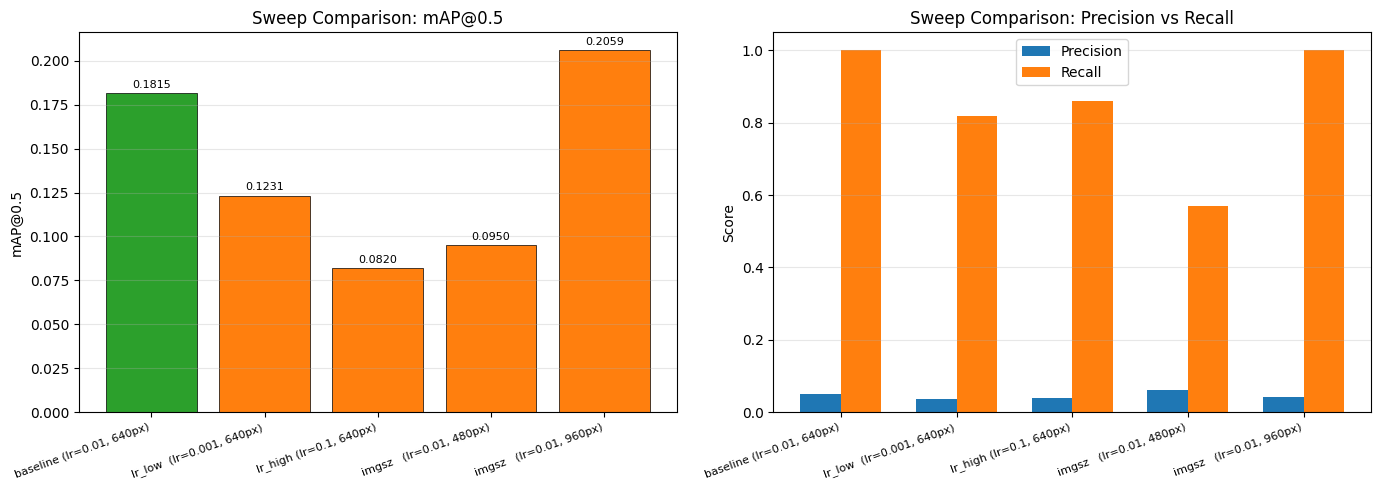

In [13]:

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
configs = sweep_df["Config"].tolist()
x = range(len(configs))
c7 = ["#2ca02c" if "baseline" in c else "#ff7f0e" for c in configs]
bars = axes[0].bar(x, sweep_df["mAP@0.5"], color=c7, edgecolor="black", linewidth=0.5)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(configs, rotation=20, ha="right", fontsize=8)
axes[0].set_ylabel("mAP@0.5")
axes[0].set_title("Sweep Comparison: mAP@0.5")
axes[0].grid(axis="y", alpha=0.3)
for bar, val in zip(bars, sweep_df["mAP@0.5"]):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.002,
                 f"{val:.4f}", ha="center", va="bottom", fontsize=8)

width = 0.35
axes[1].bar([i - width/2 for i in x], sweep_df["Precision"], width, label="Precision", color="#1f77b4")
axes[1].bar([i + width/2 for i in x], sweep_df["Recall"], width, label="Recall", color="#ff7f0e")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(configs, rotation=20, ha="right", fontsize=8)
axes[1].set_ylabel("Score")
axes[1].set_title("Sweep Comparison: Precision vs Recall")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join("runs", "detect", PROJECT_NAME, RUN_NAME, "sweep_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()


## Task 8 — Detection Visualization Gallery

Render the model's predictions (bounding boxes, class identity, confidence) and ground-truth labels side-by-side on all test grid images. Each 3×3 grid contains 9 celebrity faces; your 5 target identities (marked with `*`) are highlighted to show where the model succeeds or fails at identification.


**Note on detection evaluation metrics:**

In object detection, a *true negative* (TN) is not a meaningful metric because the
number of possible "negative" background locations is unbounded. Standard detection
evaluation therefore relies on TP, FP, and FN (and per-class AP).

We additionally report **Misclassified** detections — boxes that correctly overlap
a ground-truth face (IoU > 0.5) but are assigned the wrong identity. This distinguishes
localization errors (FP) from classification errors (Misclassified), which is useful
when the goal is both *detecting* and *identifying* celebrities.



Detection Gallery - 11 images, 13 classes
Target celebrity IDs: ['2619', '4428', '7', '7007', '797']


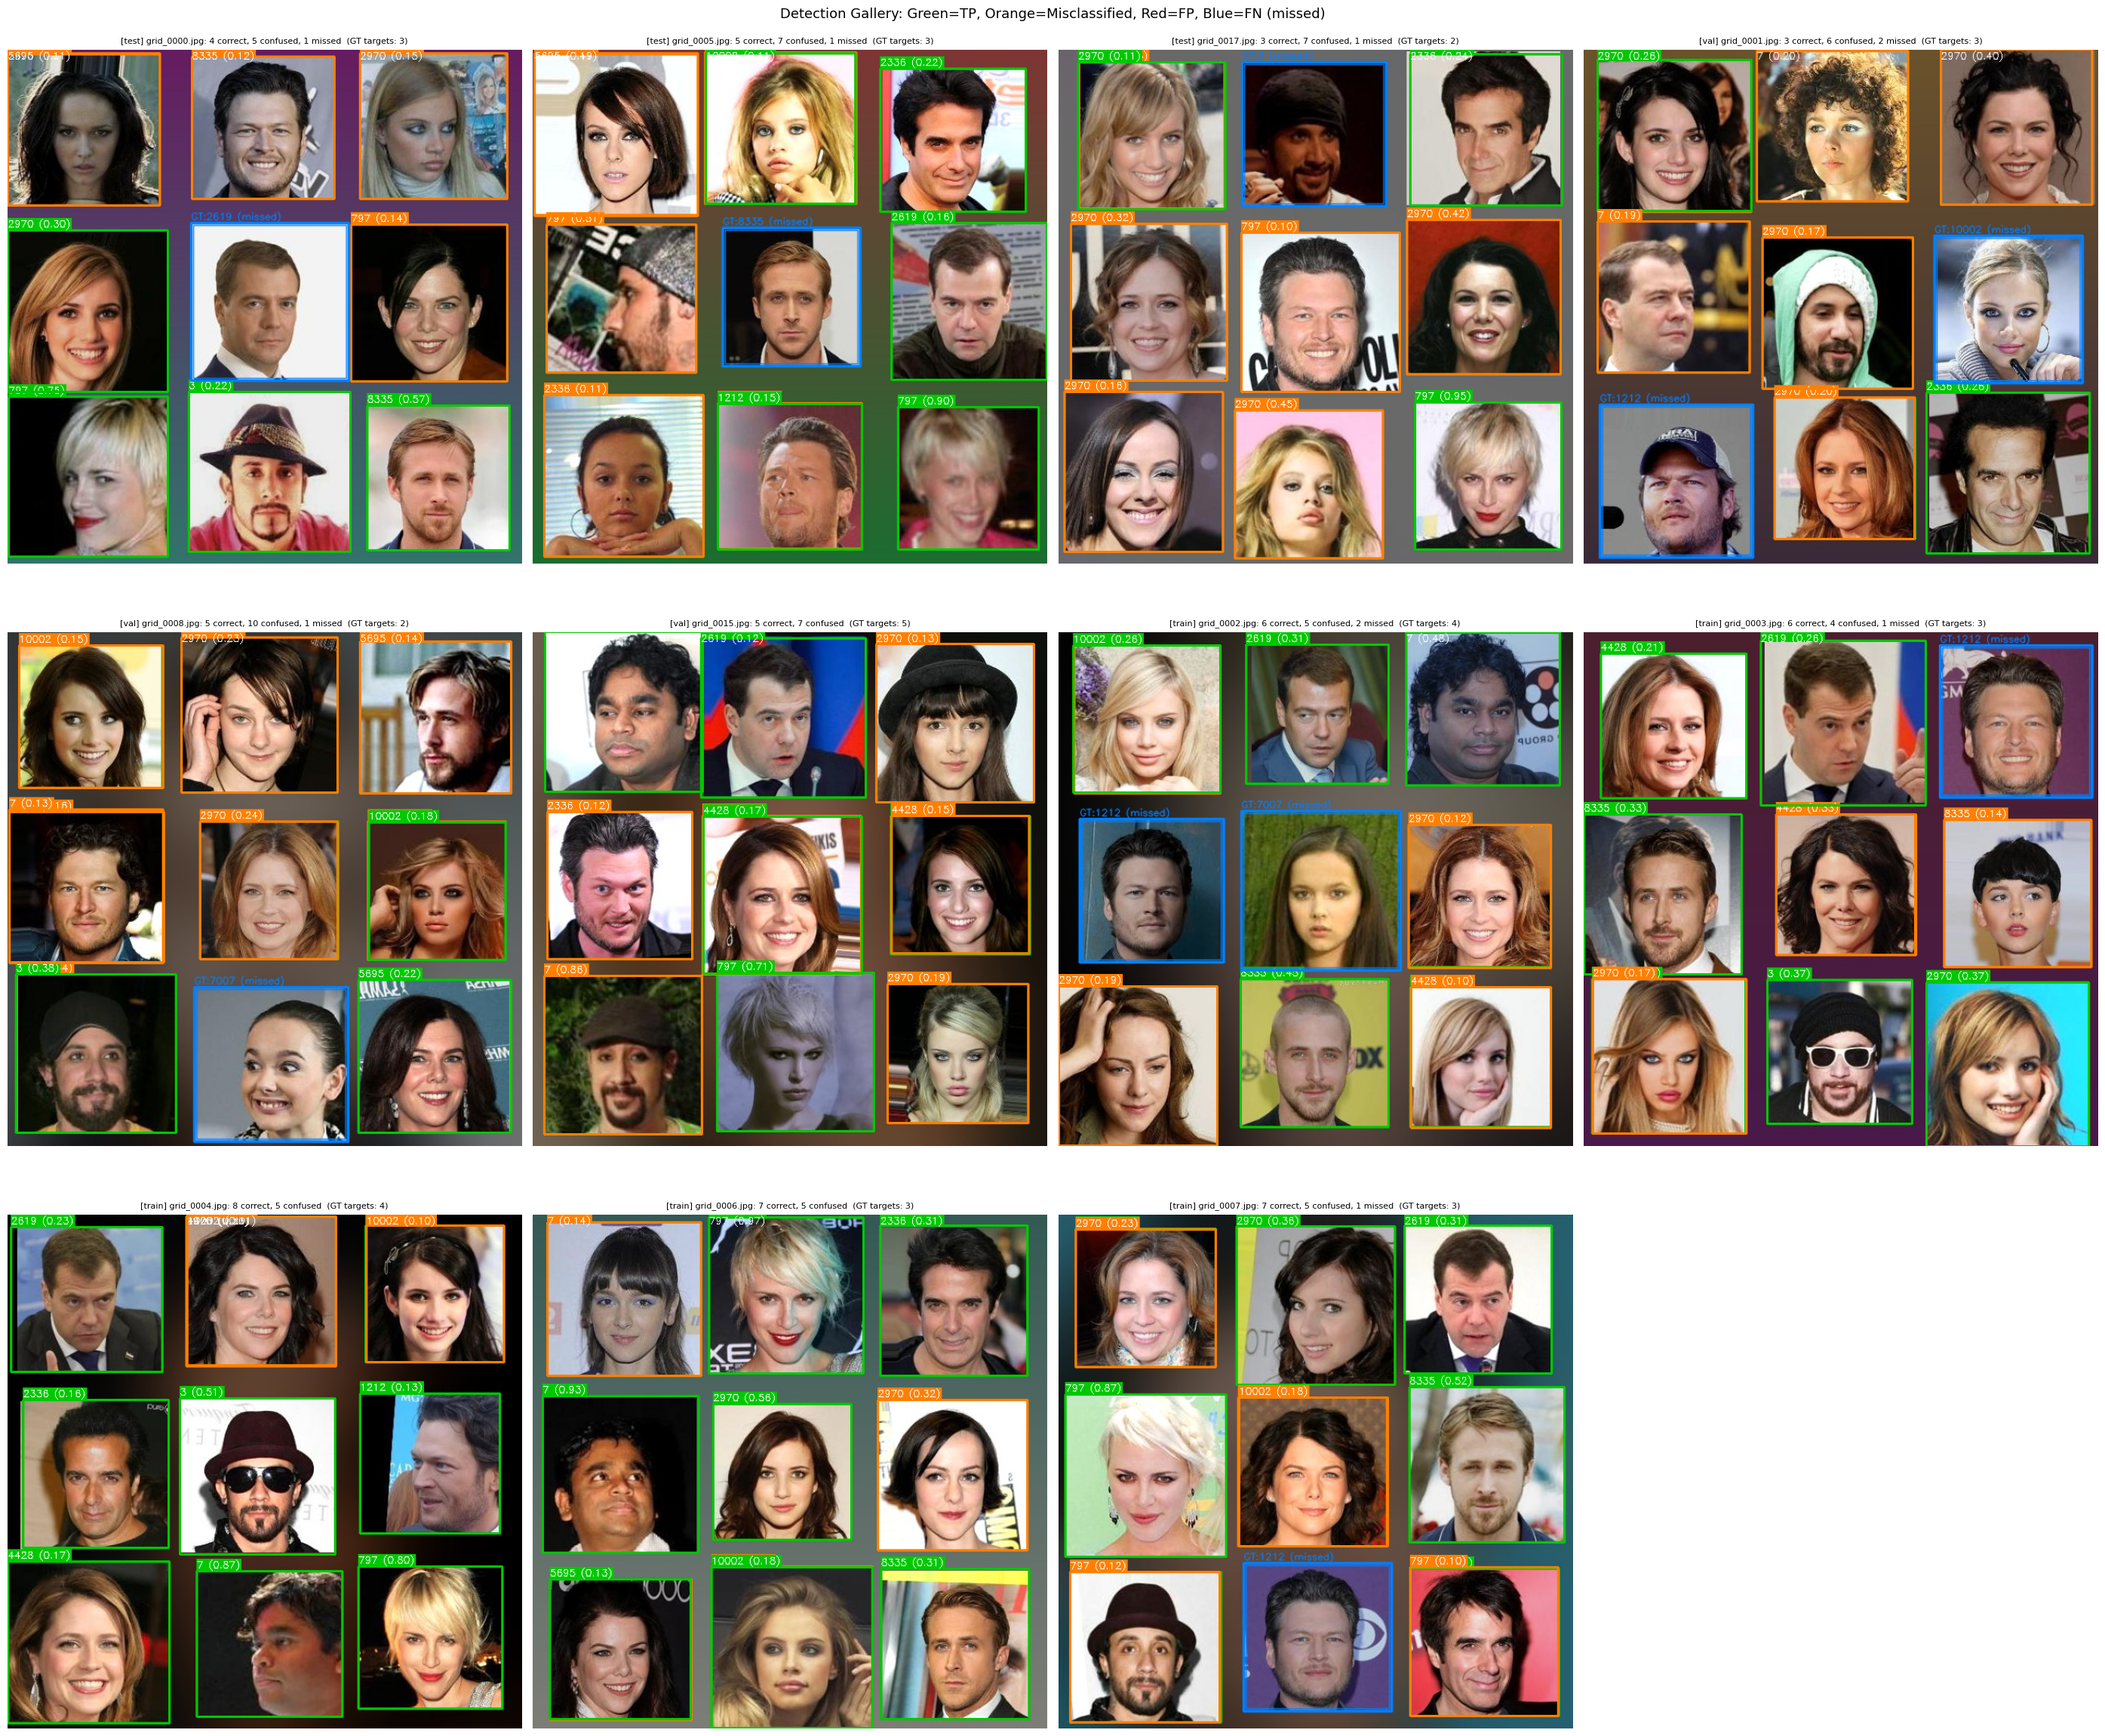


DETECTION SUMMARY  (Green=TP, Orange=Misclassified, Red=FP, Blue=FN)
  test/grid_0000.jpg: TP=4 FP=0 FN=1 Misclassified=5  [ISSUES]
  test/grid_0005.jpg: TP=5 FP=0 FN=1 Misclassified=7  [ISSUES]
  test/grid_0017.jpg: TP=3 FP=0 FN=1 Misclassified=7  [ISSUES]
  val/grid_0001.jpg: TP=3 FP=0 FN=2 Misclassified=6  [ISSUES]
  val/grid_0008.jpg: TP=5 FP=0 FN=1 Misclassified=10  [ISSUES]
  val/grid_0015.jpg: TP=5 FP=0 FN=0 Misclassified=7  [ISSUES]
  train/grid_0002.jpg: TP=6 FP=0 FN=2 Misclassified=5  [ISSUES]
  train/grid_0003.jpg: TP=6 FP=0 FN=1 Misclassified=4  [ISSUES]
  train/grid_0004.jpg: TP=8 FP=0 FN=0 Misclassified=5  [ISSUES]
  train/grid_0006.jpg: TP=7 FP=0 FN=0 Misclassified=5  [ISSUES]
  train/grid_0007.jpg: TP=7 FP=0 FN=1 Misclassified=5  [ISSUES]


In [14]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

best_weights_path = os.path.join("runs", "detect", PROJECT_NAME, RUN_NAME, "weights", "best.pt")
assert os.path.exists(best_weights_path), f"Best weights not found: {best_weights_path}"
gallery_model = YOLO(best_weights_path)
TARGET_IDS = {"7", "797", "2619", "4428", "7007"}
target_indices = {CLASS_NAMES.index(cid) for cid in TARGET_IDS if cid in CLASS_NAMES}
dataset_dir = os.path.dirname(DATA_YAML)
splits = [
    ("test",  os.path.join(dataset_dir, "images", "test"),  os.path.join(dataset_dir, "labels", "test")),
    ("val",   os.path.join(dataset_dir, "images", "val"),   os.path.join(dataset_dir, "labels", "val")),
    ("train", os.path.join(dataset_dir, "images", "train"), os.path.join(dataset_dir, "labels", "train")),
]
gallery_items = []
for sname, idir, ldir in splits:
    imgs = sorted(f for f in os.listdir(idir) if f.lower().endswith((".jpg", ".png")))
    if sname == "train": imgs = imgs[:5]
    for f in imgs: gallery_items.append((sname, f, idir, ldir))
n_imgs = len(gallery_items)
print(f"\n{'='*60}")
print(f"Detection Gallery - {n_imgs} images, {NUM_CLASSES} classes")
print(f"Target celebrity IDs: {sorted(TARGET_IDS)}")
print(f"{'='*60}")

def compute_iou(box_a, box_b):
    x1=max(box_a[0],box_b[0]); y1=max(box_a[1],box_b[1])
    x2=min(box_a[2],box_b[2]); y2=min(box_a[3],box_b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    area_a=(box_a[2]-box_a[0])*(box_a[3]-box_a[1])
    area_b=(box_b[2]-box_b[0])*(box_b[3]-box_b[1])
    union=area_a+area_b-inter
    return inter/union if union>0 else 0.0

def load_gt_boxes(lbl_path, img_w, img_h):
    boxes=[]
    if not os.path.exists(lbl_path): return boxes
    with open(lbl_path) as f:
        for line in f:
            parts=line.strip().split()
            if len(parts)<5: continue
            ci=int(parts[0])
            cx,cy,bw,bh=float(parts[1]),float(parts[2]),float(parts[3]),float(parts[4])
            x1,y1=int((cx-bw/2)*img_w),int((cy-bh/2)*img_h)
            x2,y2=int((cx+bw/2)*img_w),int((cy+bh/2)*img_h)
            boxes.append({"class":ci,"bbox":[x1,y1,x2,y2],"is_target":ci in target_indices})
    return boxes

def annotate_with_errors(img, gt_boxes, dets):
    annotated=img.copy()
    n_tp,n_fp,n_fn,n_confused=0,0,0,0
    det_list=[]
    for i in range(len(dets)):
        x1,y1,x2,y2 = map(int, dets.xyxy[i].tolist())
        ci = int(dets.cls[i].item())
        conf = float(dets.conf[i].item())
        det_list.append({"bbox":[x1,y1,x2,y2],"class":ci,"conf":conf})
    gt_matched=[False]*len(gt_boxes)
    for det in det_list:
        best_iou,best_gt_idx=0.0,-1
        for j,gt in enumerate(gt_boxes):
            iou=compute_iou(det["bbox"],gt["bbox"])
            if iou>best_iou: best_iou=iou; best_gt_idx=j
        if best_iou>0.5 and best_gt_idx>=0:
            gt=gt_boxes[best_gt_idx]
            if det["class"]==gt["class"]:
                color=(0,200,0); n_tp+=1; gt_matched[best_gt_idx]=True
            else:
                color=(0,128,255); n_confused+=1; gt_matched[best_gt_idx]=True
        else:
            color=(0,0,255); n_fp+=1
        x1,y1,x2,y2=det["bbox"]
        label=f"{CLASS_NAMES[det['class']]} ({det['conf']:.2f})"
        cv2.rectangle(annotated,(x1,y1),(x2,y2),color,2)
        (tw,th),_=cv2.getTextSize(label,cv2.FONT_HERSHEY_SIMPLEX,0.4,1)
        cv2.rectangle(annotated,(x1,max(y1-th-6,0)),(x1+tw,y1),color,-1)
        cv2.putText(annotated,label,(x1,max(y1-4,12)),cv2.FONT_HERSHEY_SIMPLEX,0.4,(255,255,255),1)
    for j,gt in enumerate(gt_boxes):
        if not gt_matched[j]:
            x1,y1,x2,y2=gt["bbox"]
            color=(255,128,0)
            cv2.rectangle(annotated,(x1,y1),(x2,y2),color,2,cv2.LINE_AA)
            cv2.rectangle(annotated,(x1+3,y1+3),(x2-3,y2-3),color,1,cv2.LINE_AA)
            label=f"GT:{CLASS_NAMES[gt['class']]} (missed)"
            cv2.putText(annotated,label,(x1,max(y1-4,12)),cv2.FONT_HERSHEY_SIMPLEX,0.4,color,1,cv2.LINE_AA)
            n_fn+=1
    return annotated, {"TP":n_tp,"FP":n_fp,"FN":n_fn,"Misclassified":n_confused}

CONF=0.1
results_log=[]
n_cols=min(4,n_imgs)
n_rows=(n_imgs+n_cols-1)//n_cols
fig,axes=plt.subplots(n_rows,n_cols,figsize=(7*n_cols,8*n_rows))
fig.suptitle("Detection Gallery: Green=TP, Orange=Misclassified, Red=FP, Blue=FN (missed)",fontsize=13)
if n_rows==1: axes=[axes]
for idx,(sname,img_name,idir,ldir) in enumerate(gallery_items):
    row=idx//n_cols; col=idx%n_cols; ax=axes[row,col]
    img_path=os.path.join(idir,img_name)
    lbl_path=os.path.join(ldir,img_name.rsplit(".",1)[0]+".txt")
    img=cv2.imread(img_path); h,w=img.shape[:2]
    gt_boxes=load_gt_boxes(lbl_path,w,h)
    preds=gallery_model.predict(img_path,conf=CONF,imgsz=IMG_SIZE,verbose=False)
    dets=preds[0].boxes
    annotated,counts=annotate_with_errors(img,gt_boxes,dets)
    parts=[]
    if counts["TP"]>0: parts.append(f"{counts['TP']} correct")
    if counts["Misclassified"]>0: parts.append(f"{counts['Misclassified']} confused")
    if counts["FP"]>0: parts.append(f"{counts['FP']} FP")
    if counts["FN"]>0: parts.append(f"{counts['FN']} missed")
    caption=f"[{sname}] {img_name}: "+(", ".join(parts) if parts else "no detections")
    n_gt_target=sum(1 for g in gt_boxes if g["is_target"])
    if n_gt_target>0: caption+=f"  (GT targets: {n_gt_target})"
    ax.imshow(cv2.cvtColor(annotated,cv2.COLOR_BGR2RGB))
    ax.set_title(caption,fontsize=8); ax.axis("off")
    results_log.append({"image":f"{sname}/{img_name}","counts":counts,"gt":len(gt_boxes),"gt_target":n_gt_target})
total_slots=n_rows*n_cols
for idx in range(n_imgs,total_slots):
    axes[idx//n_cols, idx%n_cols].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join("runs","detect",PROJECT_NAME,RUN_NAME,"detection_gallery_enhanced.png"),dpi=150,bbox_inches="tight")
plt.show()
print(f"\n{'='*60}")
print("DETECTION SUMMARY  (Green=TP, Orange=Misclassified, Red=FP, Blue=FN)")
print(f"{'='*60}")
for r in results_log:
    c=r["counts"]
    status="OK" if c["FN"]==0 and c["Misclassified"]==0 else "ISSUES"
    print(f"  {r['image']}: TP={c['TP']} FP={c['FP']} FN={c['FN']} Misclassified={c['Misclassified']}  [{status}]")


## Task 8b — Per-Target-Class Summary (Test Set)

Aggregated TP / Misclassified / FN counts for each of the 5 target celebrity identities across the **held-out test set** (3 images).


In [15]:
import pandas as pd

target_ids = ["7", "797", "2619", "4428", "7007"]
summary = {cid: {"TP": 0, "Misclassified": 0, "FN": 0} for cid in target_ids}
total_fp = 0

# Test set only
idir = os.path.join(dataset_dir, "images", "test")
ldir = os.path.join(dataset_dir, "labels", "test")
imgs = sorted(f for f in os.listdir(idir) if f.lower().endswith((".jpg", ".png")))
print(f"Test images: {len(imgs)}")

for f in imgs:
    img_path = os.path.join(idir, f)
    lbl_path = os.path.join(ldir, f.rsplit(".", 1)[0] + ".txt")

    # Load GT boxes in pixel coords
    gt_boxes = []
    if os.path.exists(lbl_path):
        img_tmp = cv2.imread(img_path)
        if img_tmp is not None:
            h, w = img_tmp.shape[:2]
            with open(lbl_path) as gf:
                for line in gf:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        ci = int(parts[0])
                        cx, cy, bw, bh = map(float, parts[1:5])
                        gt_boxes.append({
                            "class": ci,
                            "bbox": [int((cx-bw/2)*w), int((cy-bh/2)*h),
                                     int((cx+bw/2)*w), int((cy+bh/2)*h)]
                        })

    # Predict
    preds = gallery_model.predict(img_path, conf=0.1, imgsz=IMG_SIZE, verbose=False)
    dets = preds[0].boxes
    det_list = []
    for i in range(len(dets)):
        x1, y1, x2, y2 = map(int, dets.xyxy[i].tolist())
        ci = int(dets.cls[i].item())
        det_list.append({"class": ci, "bbox": [x1, y1, x2, y2]})

    # Match each GT box to best detection
    matched_det_idx = set()
    for gt in gt_boxes:
        gt_cls = gt["class"]
        cid = CLASS_NAMES[gt_cls]
        if cid not in target_ids:
            continue
        best_iou, best_det_i = 0.0, -1
        for di, det in enumerate(det_list):
            v = compute_iou(gt["bbox"], det["bbox"])
            if v > best_iou:
                best_iou = v
                best_det_i = di
        if best_iou >= 0.5 and best_det_i >= 0:
            matched_det_idx.add(best_det_i)
            if det_list[best_det_i]["class"] == gt_cls:
                summary[cid]["TP"] += 1
            else:
                summary[cid]["Misclassified"] += 1
        else:
            summary[cid]["FN"] += 1

    # Count FP
    total_fp += max(0, len(det_list) - len(matched_det_idx))

# Build table
rows = []
for cid in target_ids:
    r = summary[cid]
    gt_total = r["TP"] + r["Misclassified"] + r["FN"]
    recall = r["TP"] / gt_total if gt_total > 0 else 0.0
    rows.append({
        "Class": cid + " *",
        "TP": r["TP"],
        "Misclassified": r["Misclassified"],
        "FN (missed)": r["FN"],
        "GT Total": gt_total,
        "Recall": f"{recall:.3f}"
    })

df = pd.DataFrame(rows)
print(f"\n{'='*60}")
print("PER-TARGET-CLASS SUMMARY  (test set only, conf=0.1)")
print(f"{'='*60}")
print(df.to_string(index=False))
print(f"\nTotal False Positives (all classes combined): {total_fp}")
print("  * = target celebrity")


Test images: 3

PER-TARGET-CLASS SUMMARY  (test set only, conf=0.1)
 Class  TP  Misclassified  FN (missed)  GT Total Recall
   7 *   0              0            0         0  0.000
 797 *   3              0            0         3  1.000
2619 *   1              0            1         2  0.500
4428 *   0              1            0         1  0.000
7007 *   0              2            0         2  0.000

Total False Positives (all classes combined): 24
  * = target celebrity


## Summary

**Model:** YOLOv8 Nano (fine-tuned)

**Dataset:** 21 synthetic 3x3 grid images (14 train / 4 val / 3 test), 13 celebrity identities (Milestone 2)

**Training:** 100 epochs, batch size 16, 640x640 images, lr0=0.005, lrf=0.01

**Final Metrics:**

- mAP@0.5, mAP@0.5:0.95, Precision, Recall: See test results above
- IoU threshold: 0.50 (for mAP@0.5) / 0.50:0.95 step 0.05 (for mAP@0.5:0.95)
- Per-class breakdown: See per-class table above

**Hyperparameter Sweep:** Compared learning rate (0.001 / 0.01 / 0.03) and image size (480 / 640 / 960) to document trade-offs.

**Visualization Gallery:** 11 annotated examples (test + val + train) with predictions, ground truth, and captions explaining successes and failures.

**Live Demo:** `milestone3_demo.py` — standalone detection demo.

**Next Step:** Open `Milestone4_Pipeline_Integration.ipynb` to integrate the trained model into the `CelebrityPipeline`.
